In [14]:
import matplotlib.pyplot as plt
from keras.models import Sequential
from keras.layers import Dense, Dropout, Input
from keras.utils import to_categorical
import numpy as np
from sklearn.metrics import confusion_matrix
from keras.datasets import mnist

Text(0.5, 1.0, '3')

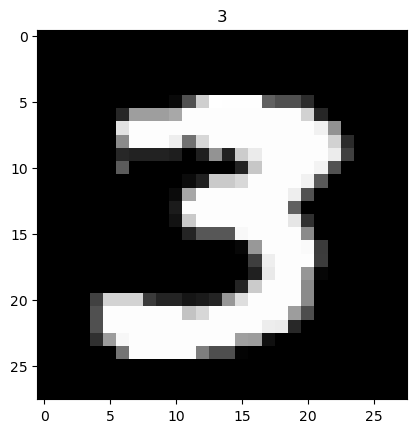

In [15]:
(X_treinamento, y_treinamento), (X_teste, y_teste) = mnist.load_data()
plt.imshow(X_treinamento[27], cmap = 'gray')
plt.title(y_treinamento[27])

In [16]:
X_treinamento = X_treinamento.reshape((len(X_treinamento), np.prod(X_treinamento.shape[1:])))
X_teste = X_teste.reshape((len(X_teste), np.prod(X_teste.shape[1:])))
X_teste[0]

array([  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
         0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
         0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
         0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
         0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
         0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
         0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
         0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
         0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
         0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
         0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
         0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
         0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
         0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   

In [17]:
X_treinamento = X_treinamento.astype('float32')
X_teste = X_teste.astype('float32')

In [18]:
X_treinamento /= 255
X_teste /= 255

In [19]:
y_treinamento = to_categorical(y_treinamento, 10)
y_teste = to_categorical(y_teste, 10)
y_teste[0]

array([0., 0., 0., 0., 0., 0., 0., 1., 0., 0.])

In [33]:
#Estrutura da rede neural: 784 - 64 - 64 - 64 - 10
#Dropout e utilizado para zerar uma porcentagem dos neuronios pra evitar overfitting
modelo = Sequential()
modelo.add(Input(shape=(784,)))
modelo.add(Dense(units = 64, activation = 'relu'))
modelo.add(Dropout(0.2))
modelo.add(Dense(units = 64, activation = 'relu'))
modelo.add(Dropout(0.2))
modelo.add(Dense(units = 64, activation = 'relu'))
modelo.add(Dropout(0.2))
modelo.add(Dense(units = 10, activation = 'softmax'))

In [21]:
modelo.summary()

Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense_5 (Dense)                      │ (None, 64)                  │          50,240 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_3 (Dropout)                  │ (None, 64)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_6 (Dense)                      │ (None, 64)                  │           4,160 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_4 (Dropout)                  │ (None, 64)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_7 (Dense)                      │ (None, 64)                  │           4,160 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_5 (Dropout)                  │ (None, 64)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_8 (Dense)                      │ (None, 10)                  │             650 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 59,210 (231.29 KB)

 Trainable params: 59,210 (231.29 KB)

 Non-trainable params: 0 (0.00 B)

In [34]:
#configuracao dos parametros da rede neural e treinamento (usando dados de validacao)
#na variavel historico se armazena o historico das execucoes de epoch (loss e accuracy)
modelo.compile(optimizer = 'adam', loss = 'categorical_crossentropy',
              metrics = ['accuracy'])
historico = modelo.fit(X_treinamento, y_treinamento, epochs = 20,
                      validation_data = (X_teste, y_teste))

Epoch 1/20
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 4s 1ms/step - accuracy: 0.8632 - loss: 0.4527 - val_accuracy: 0.9464 - val_loss: 0.1780
Epoch 2/20
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 3s 1ms/step - accuracy: 0.9330 - loss: 0.2322 - val_accuracy: 0.9611 - val_loss: 0.1342
Epoch 3/20
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 3s 1ms/step - accuracy: 0.9442 - loss: 0.1909 - val_accuracy: 0.9633 - val_loss: 0.1164
Epoch 4/20
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 3s 1ms/step - accuracy: 0.9513 - loss: 0.1664 - val_accuracy: 0.9638 - val_loss: 0.1237
Epoch 5/20
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 3s 1ms/step - accuracy: 0.9556 - loss: 0.1539 - val_accuracy: 0.9670 - val_loss: 0.1100
Epoch 6/20
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 3s 1ms/step - accuracy: 0.9592 - loss: 0.1402 - val_accuracy: 0.9682 - val_loss: 0.1053
Epoch 7/20
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 3s 1ms/step - accuracy: 0.9618 - loss: 0.1300 - val_accuracy: 0.9706 - val_loss: 0.1013
Epoch 8/20
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 3s 1ms/step - accuracy: 0.9635 - loss: 0.1247 - 

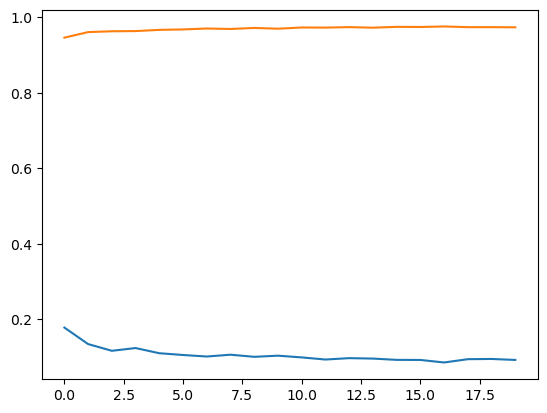

In [35]:
#grafico para visualizar loss e accuracy
historico.history.keys()
#evolucao do loss em azul
plt.plot(historico.history['val_loss'])
#performance da rede em laranja
plt.plot(historico.history['val_accuracy'])

In [36]:
#obtencao das previsoes
previsoes = modelo.predict(X_teste)
previsoes

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 785us/step


array([[2.9090649e-10, 9.3253085e-09, 7.0872545e-07, ..., 9.9999619e-01,
        8.0443562e-11, 2.5198035e-06],
       [8.0948113e-14, 8.9634875e-07, 9.9999809e-01, ..., 9.4393009e-09,
        1.7756954e-11, 5.5045918e-17],
       [2.1233027e-11, 9.9999893e-01, 1.3366079e-08, ..., 5.1184503e-07,
        5.6799661e-07, 1.3521334e-09],
       ...,
       [3.2278638e-11, 5.4128422e-09, 6.3132044e-10, ..., 1.1547864e-07,
        2.5918061e-08, 4.0995477e-05],
       [2.4499060e-15, 1.7540107e-15, 9.6923016e-15, ..., 2.9713221e-14,
        2.6467971e-08, 8.0333846e-09],
       [3.3650968e-12, 2.3005616e-14, 2.4798935e-13, ..., 9.3531696e-20,
        5.9683244e-12, 1.9171218e-16]], shape=(10000, 10), dtype=float32)

In [37]:
#armazenando o valor maximo por probabilidade maior por serem 10 saidas
#geracao da matriz de confusao
y_teste_matriz = [np.argmax(t) for t in y_teste]
y_previsoes_matriz = [np.argmax(t) for t in previsoes]
confusao = confusion_matrix(y_teste_matriz, y_previsoes_matriz)
confusao

array([[ 972,    1,    0,    1,    0,    2,    1,    1,    1,    1],
       [   0, 1123,    3,    2,    0,    0,    1,    0,    6,    0],
       [   6,    1,  989,    8,    5,    0,    1,   14,    8,    0],
       [   1,    0,    3,  991,    1,    2,    0,    6,    4,    2],
       [   1,    0,    1,    0,  951,    0,    6,    4,    2,   17],
       [   5,    0,    0,   10,    1,  859,    4,    1,    6,    6],
       [   5,    3,    0,    1,    8,    4,  934,    0,    3,    0],
       [   0,    2,    6,    2,    0,    0,    0, 1012,    1,    5],
       [   5,    0,    3,    6,    4,    5,    1,    6,  933,   11],
       [   4,    2,    0,    9,   11,    1,    0,    7,    1,  974]])

In [38]:
#exibindo valor que sera usado para teste
y_treinamento[67]

array([0., 1., 0., 0., 0., 0., 0., 0., 0., 0.])

In [39]:
#passo a mesma posicao para o modelo prever
novo = X_treinamento[67]
#conversao de matriz pra vetor
novo = np.expand_dims(novo, axis = 0)
#previsao
pred = modelo.predict(novo)
#maior valor
pred = [np.argmax(pred) for t in pred]
pred

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step


[np.int64(1)]